# Pronóstico de ventas por SKU
## Parte 3: suavizado exponencial

¿SES, Holt o Holt-Winters mejoran al mejor baseline de cada SKU?

Candidatos por SKU:
- SES en los 5 SKUs: un nivel que se actualiza solo.
- Holt en B y D: nivel más tendencia. B tiene un salto de nivel y D viene cayendo.
- Holt-Winters en A y E: nivel más estacionalidad de 12 meses. Son los dos SKUs con segundo semestre alto.
- Holt y Holt-Winters también en versión amortiguada: la tendencia se va aplanando a medida que el horizonte se aleja.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from funciones import *

In [2]:
ventas = cargar_ventas()
skus = ["A", "B", "C", "D", "E"]
cortes = pd.date_range("2022-12-01", "2024-08-01", freq="MS")

## Modelos por SKU

El primero de cada lista es el mejor baseline del notebook 02.

In [3]:
def media_movil_12(train, h):
    return media_movil(train, h, 12)

modelos = {
    "A": {"Seasonal Naive": seasonal_naive, "SES": ses, "Holt-Winters": holt_winters, "Holt-Winters amortiguado": holt_winters_amortiguado},
    "B": {"Media M12": media_movil_12, "SES": ses, "Holt": holt, "Holt amortiguado": holt_amortiguado},
    "C": {"Media": media, "SES": ses},
    "D": {"Media": media, "SES": ses, "Holt": holt, "Holt amortiguado": holt_amortiguado},
    "E": {"Naive": naive, "SES": ses, "Holt-Winters": holt_winters, "Holt-Winters amortiguado": holt_winters_amortiguado},
}

In [4]:
resultados = []
for s in skus:
    resultados.append(walk_forward(ventas, [s], modelos[s], cortes))

resultados = pd.concat(resultados)

c:\Users\agugl\OneDrive\Facultad\1_NonLinear\Tarea_entrevista\.venv\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:1065: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  res = self._optimize_parameters(res, use_brute, method, minimize_kwargs)


In [5]:
resultados

,SKU,Modelo,Corte,Horizonte,Fecha,Real,Pronostico,Escala,Error,ErrorAbs
0,A,Seasonal Naive,2022-12-01,1,2023-01-01,34,37.000000,16.73913,3.000000,3.000000
1,A,Seasonal Naive,2022-12-01,2,2023-02-01,13,25.000000,16.73913,12.000000,12.000000
2,A,Seasonal Naive,2022-12-01,3,2023-03-01,19,36.000000,16.73913,17.000000,17.000000
3,A,SES,2022-12-01,1,2023-01-01,34,43.375000,16.73913,9.375000,9.375000
4,A,SES,2022-12-01,2,2023-02-01,13,43.375000,16.73913,30.375000,30.375000
...,...,...,...,...,...,...,...,...,...,...
247,E,Holt-Winters,2024-08-01,2,2024-10-01,186,174.683036,21.44186,-11.316964,11.316964
248,E,Holt-Winters,2024-08-01,3,2024-11-01,195,152.549142,21.44186,-42.450858,42.450858
249,E,Holt-Winters amortiguado,2024-08-01,1,2024-09-01,215,162.469633,21.44186,-52.530367,52.530367
250,E,Holt-Winters amortiguado,2024-08-01,2,2024-10-01,186,174.066152,21.44186,-11.933848,11.933848


## Resultados

In [6]:
resultados.groupby(["SKU", "Modelo"]).apply(metricas).round(2)

MAE  MASE  Sesgo
SKU Modelo                                      
A   Holt-Winters              16.03  1.03   2.34
    Holt-Winters amortiguado  15.75  1.02  -1.52
    SES                       15.33  0.99   1.78
    Seasonal Naive            12.90  0.84   2.81
B   Holt                      17.92  0.82  -9.79
    Holt amortiguado          17.87  0.82  -9.83
    Media M12                 17.57  0.81 -10.39
    SES                       18.09  0.83 -12.54
C   Media                      8.06  1.07  -1.05
    SES                       10.58  1.41  -0.07
D   Holt                      41.55  1.54   1.59
    Holt amortiguado          40.17  1.49  -0.71
    Media                     34.27  1.27  -7.56
    SES                       40.15  1.49  -1.11
E   Holt-Winters              32.99  1.66 -14.34
    Holt-Winters amortiguado  35.66  1.80 -13.64
    Naive                     33.30  1.68 -11.90
    SES                       38.45  1.93 -14.98

- A: ningún modelo le gana al Seasonal Naive (0.84). Holt-Winters queda en 1.01-1.03.
- B: Holt amortiguado empata con la media móvil de 12 (0.81). SES y Holt quedan muy cerca (0.82-0.83).
- C: el SES es mucho peor que la media (1.41 contra 1.07).
- D: ninguno le gana a la media (1.27).
- E: Holt-Winters (1.66) queda prácticamente empatado con el Naive (1.68).

## Por horizonte

In [7]:
resultados.groupby(["SKU", "Modelo", "Horizonte"]).apply(metricas)["MASE"].unstack().round(2)

Horizonte                        1     2     3
SKU Modelo                                    
A   Holt-Winters              1.09  0.92  1.09
    Holt-Winters amortiguado  1.03  0.97  1.05
    SES                       0.99  1.01  0.97
    Seasonal Naive            0.82  0.86  0.83
B   Holt                      0.84  0.79  0.83
    Holt amortiguado          0.83  0.79  0.83
    Media M12                 0.84  0.76  0.82
    SES                       0.84  0.78  0.87
C   Media                     1.05  1.07  1.09
    SES                       1.18  1.45  1.60
D   Holt                      1.47  1.71  1.45
    Holt amortiguado          1.50  1.60  1.38
    Media                     1.26  1.27  1.27
    SES                       1.45  1.63  1.40
E   Holt-Winters              1.41  1.59  1.99
    Holt-Winters amortiguado  1.47  1.76  2.16
    Naive                     1.21  1.67  2.17
    SES                       1.44  1.88  2.47

- E: el Naive es mejor a 1 mes (1.21 contra 1.41), pero Holt-Winters es mejor a 2 y 3 meses (1.59 contra 1.67 y 1.99 contra 2.17).
- A: el Seasonal Naive es mejor que Holt-Winters en los tres horizontes.
- B: Holt amortiguado y la media móvil de 12 son casi iguales en los tres horizontes.

## Junio a agosto

In [8]:
jun_ago = resultados[resultados["Fecha"].dt.month.isin([6, 7, 8])]
jun_ago.groupby(["SKU", "Modelo"]).apply(metricas).round(2)

MAE  MASE  Sesgo
SKU Modelo                                      
A   Holt-Winters              18.95  1.23 -10.92
    Holt-Winters amortiguado  21.07  1.37 -14.36
    SES                       17.09  1.12 -11.70
    Seasonal Naive            14.67  0.96   1.67
B   Holt                      19.06  0.87 -13.64
    Holt amortiguado          19.04  0.87 -13.44
    Media M12                 20.09  0.91 -15.19
    SES                       20.88  0.95 -17.01
C   Media                      7.61  0.99  -2.99
    SES                       13.64  1.79   0.62
D   Holt                      46.58  1.70 -27.67
    Holt amortiguado          46.02  1.68 -27.22
    Media                     36.48  1.32 -12.54
    SES                       46.19  1.68 -28.63
E   Holt-Winters              37.75  1.99 -36.50
    Holt-Winters amortiguado  39.79  2.11 -38.47
    Naive                     50.83  2.64 -49.61
    SES                       56.72  2.92 -56.72

- En E, Holt-Winters es el mejor en la temporada objetivo (1.99 contra 2.64 del Naive).
- En B, Holt y Holt amortiguado (0.86-0.87) quedan mejor que la media móvil de 12 (0.91).
- En A, C y D gana el baseline.

## Primera y segunda mitad de los cortes

In [9]:
primera = resultados[resultados["Corte"] < "2023-10-01"]
segunda = resultados[resultados["Corte"] >= "2023-10-01"]

pd.DataFrame({
    "1ra mitad": primera.groupby(["SKU", "Modelo"]).apply(metricas)["MASE"],
    "2da mitad": segunda.groupby(["SKU", "Modelo"]).apply(metricas)["MASE"],
}).round(2)

1ra mitad  2da mitad
SKU Modelo                                        
A   Holt-Winters                   1.35       0.74
    Holt-Winters amortiguado       1.31       0.75
    SES                            0.95       1.02
    Seasonal Naive                 0.89       0.79
B   Holt                           0.65       0.98
    Holt amortiguado               0.64       0.99
    Media M12                      0.60       0.99
    SES                            0.60       1.04
C   Media                          1.14       1.00
    SES                            1.53       1.31
D   Holt                           2.01       1.12
    Holt amortiguado               1.99       1.04
    Media                          1.78       0.80
    SES                            1.97       1.06
E   Holt-Winters                   2.25       1.13
    Holt-Winters amortiguado       2.52       1.14
    Naive                          1.93       1.46
    SES                            2.39       1.51

- Holt-Winters mejora mucho en la segunda mitad: en A pasa de 1.35 a 0.74 y en E de 2.25 a 1.13. En los dos es el mejor de la segunda mitad.
- En la primera mitad entrena con 24 a 33 meses, apenas dos ciclos para estimar 12 índices estacionales. El pronóstico final se entrena con 53 meses, más parecido a la segunda mitad.
- En C y D la media gana en las dos mitades.

## Pronóstico a 1 mes contra lo real

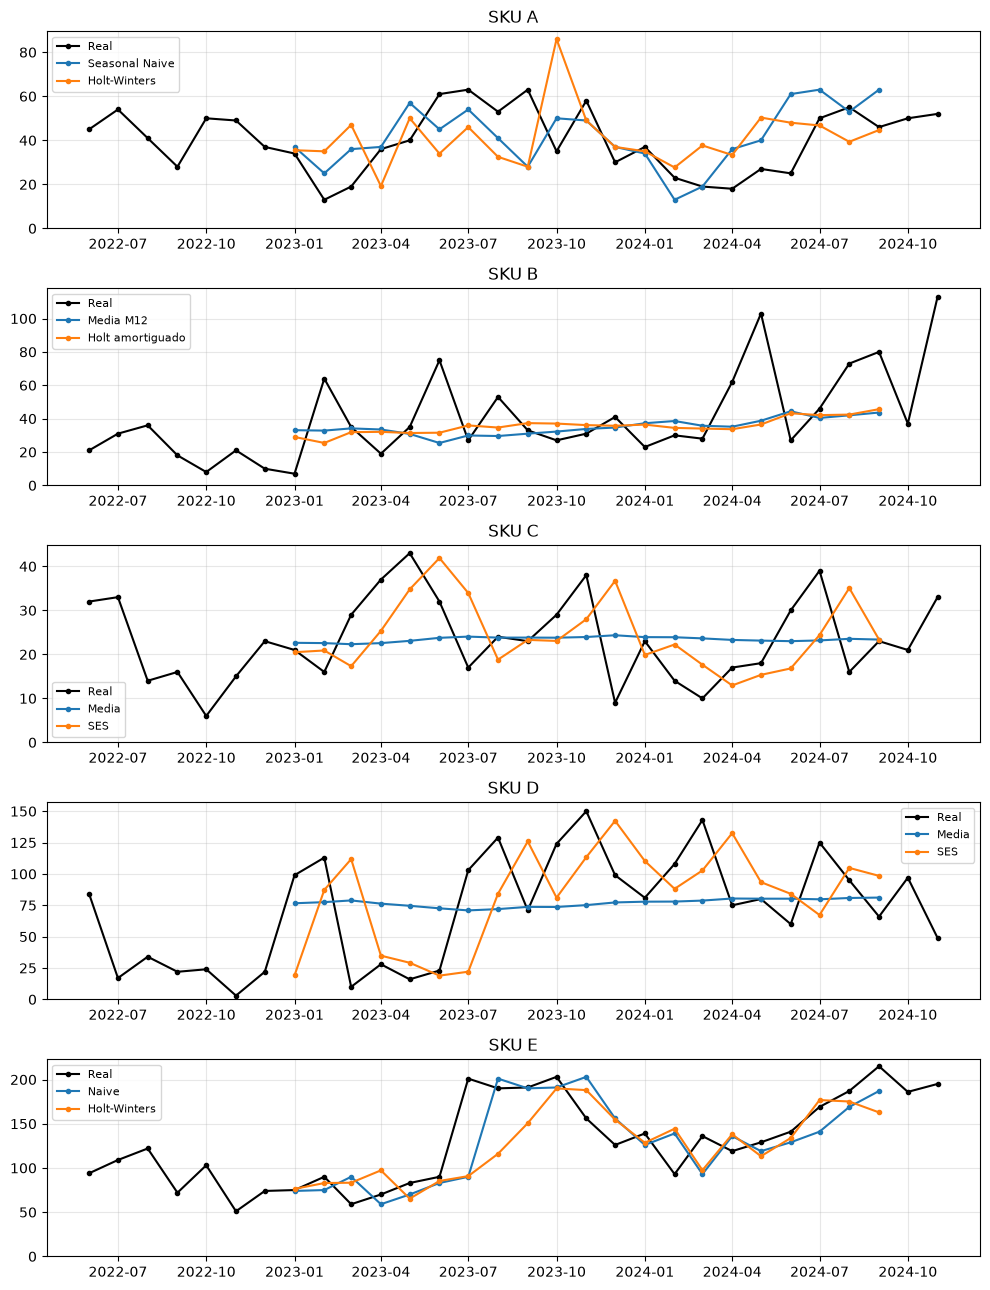

In [11]:
comparar = {
    "A": ["Seasonal Naive", "Holt-Winters"],
    "B": ["Media M12", "Holt amortiguado"],
    "C": ["Media", "SES"],
    "D": ["Media", "SES"],
    "E": ["Naive", "Holt-Winters"],
}

un_mes = resultados[resultados["Horizonte"] == 1]
fig, axes = plt.subplots(5, 1, figsize=(10, 13))

for i, s in enumerate(skus):
    axes[i].plot(ventas.loc["2022-06-01":"2024-11-01", s], color="black", marker="o", markersize=3, label="Real")
    for nombre in comparar[s]:
        p = un_mes[(un_mes["SKU"] == s) & (un_mes["Modelo"] == nombre)]
        axes[i].plot(p["Fecha"], p["Pronostico"], marker="o", markersize=3, label=nombre)
    axes[i].set_title(f"SKU {s}")
    axes[i].set_ylim(bottom=0)
    axes[i].grid(alpha=0.3)
    axes[i].legend(fontsize=8)

plt.tight_layout()
plt.show()

## Selección del modelo

Para elegir comparo todos los candidatos: los 6 baselines del notebook 02 y los modelos de suavizado de este notebook. Regla: menor MASE promedio de los horizontes 1 a 3 y, si la diferencia es menor a 0.05, gana el más simple.

In [12]:
baselines = {
    "Naive": naive,
    "Seasonal Naive": seasonal_naive,
    "Media": media,
    "Media M3": lambda train, h: media_movil(train, h, 3),
    "Media M6": lambda train, h: media_movil(train, h, 6),
    "Media M12": media_movil_12,
}

todos = pd.concat([resultados, walk_forward(ventas, skus, baselines, cortes)])
todos = todos.drop_duplicates(["SKU", "Modelo", "Corte", "Horizonte"])
todos["MASE"] = todos["ErrorAbs"] / todos["Escala"]
todos["Peso"] = todos["Corte"].rank(method="dense")

### Primer criterio: todos los cortes pesan igual

In [19]:
igual_peso = todos.groupby(["SKU", "Modelo"])["MASE"].mean().reset_index()
igual_peso.sort_values(["SKU", "MASE"]).groupby("SKU").head(3).round(2)

,SKU,Modelo,MASE
8,A,Seasonal Naive,0.84
6,A,Naive,0.92
2,A,Media,0.94
12,B,Media M12,0.81
10,B,Holt amortiguado,0.82
9,B,Holt,0.82
18,C,Media,1.07
19,C,Media M12,1.20
21,C,Media M6,1.24
27,D,Media,1.27


Con este criterio la selección era:

| SKU | Modelo | MASE |
|---|---|---|
| A | Seasonal Naive | 0.84 |
| B | Media M12 | 0.81 |
| C | Media | 1.07 |
| D | Media | 1.27 |
| E | Naive | 1.68 (empata con Holt-Winters, 1.66, y gana por ser más simple) |

### Segundo criterio: los cortes recientes pesan más

Cambié a un peso lineal: el primer corte (diciembre 2022) pesa 1, el segundo 2, y así hasta el último (agosto 2024), que pesa 21. La segunda mitad queda con el 76% del peso.

Por qué:
- Las series cambian. B saltó en mayo 2024, E en julio 2023 y D salió de su período raro a mediados de 2023. Lo reciente se parece más a junio-agosto 2025 que lo de principios de 2023.
- El modelo final se entrena con 53 meses. Los cortes recientes entrenan con 34 a 44 meses, más parecido a eso que los primeros, que entrenan con 24 a 33. Holt-Winters, que necesita más historia, queda castigado en los primeros cortes.
- No uso solo la segunda mitad porque son pocos cortes y el ganador cambia por azar. Con el peso lineal uso todos los cortes, pero los recientes cuentan más.

También probé pesar más los horizontes lejanos (20%, 30% y 50% para 1, 2 y 3 meses). La selección no cambia, así que dejé los tres horizontes con el mismo peso: junio, julio y agosto importan igual en el pronóstico final.

In [20]:
def mase_ponderado(g):
    return (g["MASE"] * g["Peso"]).sum() / g["Peso"].sum()

peso_lineal = todos.groupby(["SKU", "Modelo"]).apply(mase_ponderado).reset_index(name="MASE")
peso_lineal.sort_values(["SKU", "MASE"]).groupby("SKU").head(3).round(2)

,SKU,Modelo,MASE
8,A,Seasonal Naive,0.87
6,A,Naive,0.87
2,A,Media,0.92
13,B,Media M3,0.92
9,B,Holt,0.92
12,B,Media M12,0.93
18,C,Media,0.98
21,C,Media M6,1.09
19,C,Media M12,1.10
27,D,Media,0.99


- C y D: la media gana con los dos criterios.
- E: Holt-Winters pasa a ganar con claridad (1.47 contra 1.58 del Naive).
- B: la media móvil de 3 meses pasa al primer lugar, pero empata con Holt, Holt amortiguado y la media móvil de 12 (todos entre 0.92 y 0.93).
- A: el Seasonal Naive sigue primero, pero empata con el Naive y la media.

## Conclusiones

- En C y D el suavizado exponencial no aporta: la media es la mejor opción con cualquier criterio.
- En E, Holt-Winters es el mejor cuando se le da más peso a lo reciente: es mejor a 2 y 3 meses, en junio-agosto y en la segunda mitad.
- En A y B no hay un ganador claro: varios modelos empatan. La elección casi no cambia el error.

Selección final, con peso lineal por corte:

| SKU | Modelo | MASE | Qué tan firme es |
|---|---|---|---|
| A | Seasonal Naive | 0.87 | Débil: empata con Naive y Media |
| B | Media M3 | 0.92 | Débil: empata con Media M12 y Holt |
| C | Media | 0.98 | Firme |
| D | Media | 0.99 | Firme |
| E | Holt-Winters | 1.47 | Firme |

Esta selección queda congelada para el notebook 04, donde se evalúa una sola vez en el test (diciembre 2024 a mayo 2025).